# RMSProp (Root Mean Square Propagation)

## Problem with AdaGrad
- $v_t$ is a plain sum of all past squared gradients, so it only grows.
- A growing $v_t$ makes $\frac{\eta}{\sqrt{v_t + \epsilon}}$ shrink toward zero.
- Late in training the updates become too small and learning stalls.

## Idea
- Do not sum all past gradients. Take an exponentially decaying average of the squared gradients instead.
- Recent gradients count more, old gradients fade away.

## Symbols
- $\nabla w_t = \frac{\partial L}{\partial w}$ = gradient of the loss $L$ at step $t$
- $v_t$ = decaying average of squared gradients
- $\beta$ = decay rate, usually $0.95$ (the slide uses this value)
- $\eta$ = base learning rate
- $\epsilon$ = tiny number so we never divide by zero

## Formulas

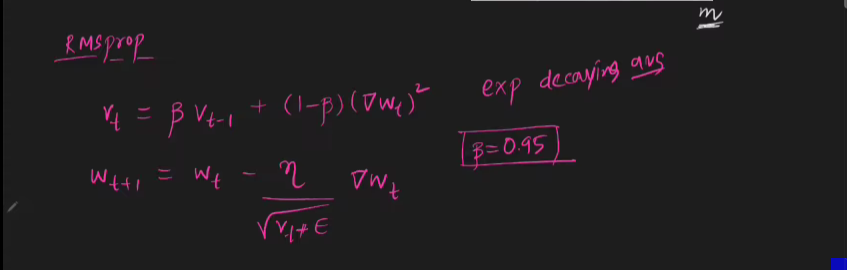

$$
v_t = \beta \, v_{t-1} + (1 - \beta)(\nabla w_t)^2
$$

$$
w_{t+1} = w_t - \frac{\eta}{\sqrt{v_t + \epsilon}} \, \nabla w_t
$$

- The update rule is identical to AdaGrad. Only the way $v_t$ is built changes.
- Same formulas for $b$.

## Why it fixes the shrinking learning rate

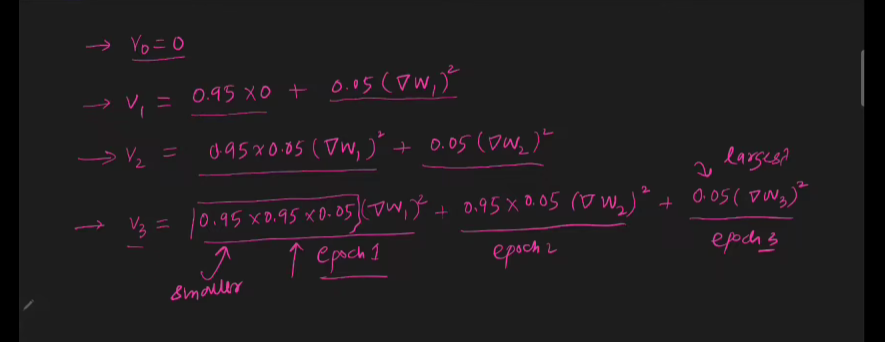
- Unrolling $v_t$ gives weights on past squared gradients:
  - current gradient: weight $(1-\beta)$
  - one step ago: weight $(1-\beta)\beta$
  - two steps ago: weight $(1-\beta)\beta^2$, and so on
- Since $\beta < 1$, the weight $\beta^k$ drops quickly as $k$ grows, so old gradients are almost forgotten.
- $v_t$ no longer grows forever. It settles around the typical size of recent squared gradients.
- So $\eta_{\text{eff}} = \frac{\eta}{\sqrt{v_t + \epsilon}}$ stays at a useful size instead of shrinking to zero.

## What $\beta$ controls
- $\beta$ close to $1$ (like $0.95$): long memory, $v_t$ changes slowly.
- Smaller $\beta$: short memory, $v_t$ follows recent gradients closely.

## AdaGrad vs RMSProp
- AdaGrad: $v_t$ = sum of all past squared gradients, learning rate keeps shrinking.
- RMSProp: $v_t$ = decaying average of recent squared gradients, learning rate stays usable.
- Both still give a per-parameter learning rate: big gradients get a small rate, small gradients get a big rate.

- <text style="color:orange"> So RMSProp is a fix for AdaGrad's shrinking learning rate problem. And finally reaches the global minimum. </text>

- <text style="color:orange"> There is no disadvantage of RMSProp. It is one of the best optimizers for Neural Networks. </text>

- Infact before Adam optimizer was invented, RMSProp was the best optimizer for Neural Networks. Now also if we don't get good results with Adam, we can try RMSProp. It is still a very good optimizer for Neural Networks.